# Estatística Geral

## Estimação de parâmetros estatísticos


Essencialmente, qualquer característica de uma população pode ser estimada a partir de uma amostra aleatória. Entre os estimadores mais comuns estão a média amostral (x̄), o desvio padrão amostral (s) e a proporção amostral (p̂) como estimadores da média populacional (μ), do desvio padrão populacional (σ) e da proporção populacional (p), respectivamente.

### Estimativa pontual:

A estimativa é pontual quando a estatística amostral origina uma única estimativa do parâmetro, ou seja, um único valor para o parâmetro populacional que se quer estimar, como, por exemplo:

| Parâmetro populacional | Estimador |
|---|---|
| $\mu$ | $\bar{x} = \dfrac{1}{n} \sum_{i=1}^{n} x_i$ |
| $\sigma$ | $s = \sqrt{\dfrac{\sum_{i=1}^{n} (x_i - \bar{x})^2}{n - 1}}$ |
| $p$ | $\hat{p} = \dfrac{x}{n}$, em que $x$ é o número de itens da amostra com a característica de interesse e $n$ é o tamanho da amostra |

### Estimativa intervalar ou Intervalo de confiança:

A estimativa é intervalar quando, a partir da estatística amostral, construímos um intervalo de valores possíveis no qual se admite, sob certa probabilidade, esteja contido o parâmetro populacional. Um intervalo de confiança está associado a um grau de confiança que é uma medida da nossa certeza de que o intervalo contém o parâmetro populacional.

O grau de confiança é a probabilidade 1 - α de o intervalo de confiança conter o verdadeiro valor do parâmetro populacional (o grau de confiança é também chamado de nível de confiança ou de coeficiente de confiança). A definição de grau de confiança utiliza α para descrever uma probabilidade que corresponde a uma área. Observe a figura abaixo:

A área central, $1 - \alpha$, é o grau de confiança; cada cauda fica com $\alpha/2$:

In [1]:
# Funções auxiliares usadas para desenhar os gráficos deste notebook
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm, t


def virgula(ax):
    """Mostra os números dos eixos com vírgula decimal."""
    fmt = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)


def duas_caudas(dist, critico, rotulos_x, rotulo_centro, rotulo_cauda, titulo=None):
    """Curva com as duas caudas além de ±critico sombreadas (intervalo de confiança)."""
    x = np.linspace(-4, 4, 400)
    fig, ax = plt.subplots(figsize=(5, 2.8))
    ax.plot(x, dist.pdf(x), color="tab:blue")
    for xs in (np.linspace(-4, -critico, 100), np.linspace(critico, 4, 100)):
        ax.fill_between(xs, dist.pdf(xs), color="0.45")
    ax.vlines([-critico, critico], 0, dist.pdf(critico), color="k", lw=1.5)
    ax.text(0, dist.pdf(0) * 0.45, rotulo_centro, ha="center", fontsize=11)
    for lado in (-1, 1):
        ax.annotate(rotulo_cauda, xy=(lado * (critico + 0.35), dist.pdf(critico) * 0.3),
                    xytext=(lado * 3.3, dist.pdf(0) * 0.45), ha="center", fontsize=11,
                    arrowprops=dict(arrowstyle="->"))
    ax.set_xticks([-critico, critico])
    ax.set_xticklabels(rotulos_x)
    ax.set_yticks([])
    ax.set_ylim(bottom=0)
    if titulo:
        ax.set_title(titulo, fontsize=10)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.show()

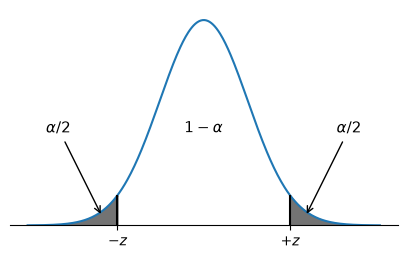

In [2]:
duas_caudas(norm, 1.96, ["$-z$", "$+z$"], "$1 - \\alpha$", "$\\alpha/2$")

São escolhas comuns para o nível de confiança: 90% (com α=0,10), 95% (com α=0,05) e 99% (com α=0,01). A mais comum é a opção 95%, porque proporciona um bom equilíbrio entre a precisão (refletida na amplitude do intervalo de confiança) e a confiabilidade (expressa pelo grau de confiança).

Quanto maior o nível de confiança, maior será a amplitude do intervalo. Dado
um nível de confiança, quanto maior for o intervalo, menos informação teremos sobre o verdadeiro valor do parâmetro populacional.

A interpretação de um intervalo de confiança é que se um número infinito de
amostras aleatórias for coletado e um intervalo com 100(1-α)% de confiança para o parâmetro for calculado a partir de cada amostra, então 100(1-α)% desses intervalos conterão o valor verdadeiro do parâmetro.

Na prática, obtemos somente uma amostra aleatória e calculamos o intervalo de
confiança. Uma vez que este intervalo conterá ou não o valor verdadeiro do parâmetro, não é razoável fixar um nível de probabilidade a esse evento específico. A afirmação apropriada é: o intervalo observado contém o valor verdadeiro do parâmetro, com 100(1-α)% de confiança.

### Intervalo de confiança para a média quando σ é conhecido:

Em uma indústria de cerveja, a quantidade de cerveja inserida em latas tem-se comportado como uma variável aleatória distribuída normalmente com média 350 ml e desvio padrão 3 ml. Após alguns problemas na linha de produção, suspeita-se que houve alteração na média. Uma amostra de 120 latas acusou média 346 ml.

Encontre a estimativa pontual e construa um intervalo de confiança para o novo valor da quantidade média de cerveja inserida em latas, com nível de confiança de 95%, supondo que não tenha ocorrido alteração no desvio padrão do processo.
A média amostral (x̄) é a melhor estimativa pontual da média populacional (μ), com base nos dados amostrais vemos que a melhor estimativa para a quantidade média de cerveja inserida nas latas, após os problemas na linha de produção, é 346ml.

Para construirmos o intervalo de confiança desejado é necessário analisar o
seguinte: Pelo Teorema Central do Limite, sabemos que as médias amostrais tendem a distribuir-se normalmente, além disso, foi-nos fornecido no enunciado do problema o valor do desvio padrão da população (σ = 3 ml). Dessa maneira, para encontrarmos o intervalo de confiança para a média vamos utilizar a distribuição normal:

Intervalo de confiança para $\mu$ quando o desvio padrão populacional $\sigma$ é conhecido:

$$\bar{x} \pm z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}}$$

O valor crítico está na fronteira que separa as médias amostrais passíveis de ocorrerem, das médias amostrais que provavelmente não ocorrerão. Ele é obtido pela tabela da distribuição normal padrão de acordo com a área desejada. Em outras palavras, o valor crítico é o valor 'z' correspondente a uma probabilidade é α/2.

O valor crítico é denotado por:

$$z_{\alpha/2}$$

Para os níveis de confiança mais utilizados, os valores críticos obtidos na
tabela da distribuição normal padrão são:

| Grau de confiança | $\alpha$ | $z_{\alpha/2}$ |
|---|---|---|
| 90% | 0,10 | 1,64 |
| 95% | 0,05 | 1,96 |
| 99% | 0,01 | 2,58 |

Valores arredondados para duas casas; a célula abaixo calcula-os com o `scipy`.

In [3]:
# Valores críticos z de alfa/2 para os níveis de confiança mais usados
from scipy.stats import norm

for confianca in (0.90, 0.95, 0.99):
    alfa_ic = 1 - confianca
    print(f"{confianca:.0%}: alfa = {alfa_ic:.2f}, z = {norm.ppf(1 - alfa_ic / 2):.4f}")

90%: alfa = 0.10, z = 1.6449
95%: alfa = 0.05, z = 1.9600
99%: alfa = 0.01, z = 2.5758


Quando utilizamos dados amostrais para estimar uma média populacional μ, a
margem de erro, denotada por E, é a diferença máxima provável (com probabilidade 1-α) entre a média amostral observada x e a verdadeira média populacional x̄. A margem de erro é chamada também de erro máximo da estimativa e pode ser obtida multiplicando-se o valor crítico pelo desvio-padrão das médias amostrais. A fómula da margem de erro (E) é:

$$E = z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}}$$

Voltando ao exemplo, temos:

- $\bar{x} = 346$ ml
- $n = 120$
- $\sigma = 3$ ml
- nível de confiança de 95%, ou seja, $\alpha = 0{,}05$

E o intervalo de confiança desejado é:

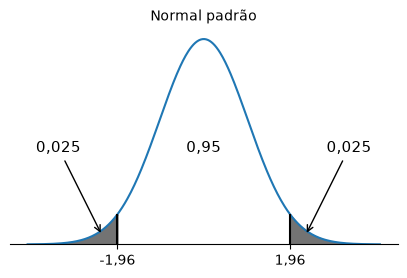

In [4]:
# 95% de confiança: 0,025 em cada cauda, valores críticos ±1,96
duas_caudas(norm, norm.ppf(0.975), ["-1,96", "1,96"], "0,95", "0,025", titulo="Normal padrão")

ou seja, 0,95/2=0,475. A partir daí, é necessário buscar na tabela da distribuição normal padrão, o valor mais próximo de 0,475 e então verificar o valor de z correspondente, que, nesse caso, é 1,96.

A margem de erro (E):

$$E = z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}} = 1{,}96 \cdot \frac{3}{\sqrt{120}} \approx 0{,}5368 \text{ ml}$$

O intervalo de confiança será I.C. =[x̄-E ; x̄+E ] = [346-0,5368 ; 346+0,5368] = [345,46 ml ; 346,54 ml]. Dessa maneira, pode-se afirmar com 95% de confiança que a quantidade média de cerveja inserida nas latas varia de 345,46 ml a 346,54 ml.

In [32]:
z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [33]:
# Informar o Grau de confiança, exemplo 90% = 90
# Primeiramente, carregar a tabela z acima.
def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

Z(95)

1.96

In [31]:
#Calculando I.C para média quando σ é conhecido.

#Variáveis do enunciado:
Média_amostral = 346
N_amostras = 120
Desvio_populacional = 3
Grau_de_conf = 95 #(%)

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_médias_amostrais = Desvio_populacional/(N_amostras**0.5)

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_médias_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Média_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1} a {2}" .format(Grau_de_conf, Média_amostral-E, Média_amostral+E))

Valor de Alpha:  0.05
Valor crítico:  1.96
Margem de Erro:  0.5368
I.C = [346-0.5368 ; 346+0.5368]


Pode-se afirmar com 95% de confiança que a média varia de 345.4632 a 346.5368


O diretor do comitê de admissão de uma universidade deseja estimar a média de idade de todos os estudantes aprovados no momento. Sabe-se que, de levantamentos anteriores, o desvio padrão da população é de 1,5 ano. Em uma amostra aleatória de 20 estudantes, a idade média encontrada foi de 22,9 anos.
- a) Com base nessa amostra, qual é a estimativa pontual da idade média dos estudantes aprovados? 
    R:De acordo com o enunciado a média é 22,9 anos. A média pontual é igual a média amostral.

- b) Construa um intervalo de 90% de confiança para a idade média da população. R:z de a/2 =1,64, E=0,5501, IC=[22,3499 ; 23,4501]

In [35]:
#Calculando I.C para média quando σ é conhecido.

#Variáveis do enunciado:
Média_amostral = 22.9 #anos
N_amostras = 20 #estudantes
Desvio_populacional = 1.5 #ano
Grau_de_conf = 90 #(%)

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_médias_amostrais = Desvio_populacional/(N_amostras**0.5)

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_médias_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Média_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f}" .format(Grau_de_conf, Média_amostral-E, Média_amostral+E))

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  0.5501
I.C = [22.9-0.5501 ; 22.9+0.5501]


Pode-se afirmar com 90% de confiança que a média varia de  22.3499 a  23.4501


Um investidor planeja abrir uma agência de viagens e deseja estimar o faturamento médio mensal em dólares. Suponha que os faturamentos mensais de agências de viagens, do porte que o investidor pretende abrir, se distribuam normalmente com um desvio padrão de US$130,00. Durante nove meses, o investidor anotou o faturamento líquido mensal de uma agência de viagem do mesmo porte. Os dados encontram-se abaixo:
    
    3810 3690 3350 3400 3320 3250 3430 3600 3670
        
Construa e interprete um intervalo de 92% de confiança para o faturamento médio mensal de uma agência de viagem desse porte. R: x = 3502,22 ; z de a/2 =1,75 ; I.C.=[3426,38 ; 3578,05]

In [37]:
import numpy as np
Dados = [3810, 3690, 3350, 3400, 3320, 3250, 3430, 3600, 3670]

In [40]:
#Calculando I.C para média quando σ é conhecido.

#Variáveis do enunciado:
Média_amostral = round(np.mean(Dados),4) #dólares
N_amostras = 9 #meses
Desvio_populacional = 130 #dólares
Grau_de_conf = 92 #(%)

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_médias_amostrais = Desvio_populacional/(N_amostras**0.5)

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_médias_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Média_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f}" .format(Grau_de_conf, Média_amostral-E, Média_amostral+E))

Valor de Alpha:  0.08
Valor crítico:  1.75
Margem de Erro:  75.8333
I.C = [3502.2222-75.8333 ; 3502.2222+75.8333]


Pode-se afirmar com 92% de confiança que a média varia de 3426.3889 a 3578.0555


### Determinação do tamanho da amostra:

Partindo da expressão da margem de erro (E) e resolvendo em relação ao tamanho
da amostra n, obtemos:

$$E = z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}} \quad \Rightarrow \quad \sqrt{n} = \frac{z_{\alpha/2} \cdot \sigma}{E} \quad \Rightarrow \quad n = \left(\frac{z_{\alpha/2} \cdot \sigma}{E}\right)^2$$

O tamanho da amostra deve ser um número inteiro, mas os cálculos para o tamanho amostral n quase nunca resultam em um número inteiro. Quando isto ocorrer, devemos sempre aumentar o valor de n para o próximo inteiro maior. Essa regra de arredondamento baseia-se no princípio de que, quando o arredondamento se faz
necessário, o tamanho da amostra deve ser arredondado para cima, a fim de ser ao menos adequadamente grande, em oposição à ligeiramente menor.

A fórmula para o cálculo do tamanho amostral utiliza o valor de σ (desvio padrão populacional), e se σ não for conhecido? Podemos então utilizar um valor preliminar obtido por processos como os que se seguem:
1. Utilizar a regra prática para estimar o desvio padrão da seguinte maneira:
    σ = Amplitude/4
2. Realizar um estudo piloto, iniciando o processo de amostragem. Com base na coleção de pelo menos 31 valores amostrais selecionados aleatoriamente, calcular o desvio padrão amostral s e utiliza-lo no lugar de σ.

### Exemplo:
Um economista deseja estimar a renda média de bacharéis em Economia que tiveram a feliz idéia de fazer um curso de Estatística. Quantos valores de renda devem ser tomados, se o economista deseja ter 95% de confiança em que a média amostral esteja a menos de RS 500,00 da verdadeira média populacional? Suponha que saibamos, por um estudo prévio, que, para tais rendas, σ = RS 6250,00. Queremos determinar o tamanho n da amostra, dado que α = 0,05 (95% de confiança). Desejamos que a média amostral esteja a menos de R$ 500,00 da média populacional, ouse já, queremos que a margem de erro seja E=500. Supondo σ =6250, aplicamos a fórmula do tamanho amostral, obtendo:

$$n = \left(\frac{z_{\alpha/2} \cdot \sigma}{E}\right)^2 = \left(\frac{1{,}96 \cdot 6250}{500}\right)^2 = 600{,}25 \quad \Rightarrow \quad n = 601 \text{ (arredondando para cima)}$$

Refaça esse exercício considerando agora:
- a) Margem de erro igual a RS 1000,00. R:n=150,0625, ou seja, 151

In [48]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 1000 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 6250 #reais
Grau_de_conf = 95 #(%)

N_finita = False
N_populacional = 0

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.05
Valor crítico:  1.96
Margem de Erro:  1000
O número de amostras ideal é:  151.0


Refaça esse exercício considerando agora:
- b) Margem de erro igual a RS 250,00 e nível de confiança de 85%. R:z =1,44, n=1296

In [44]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 250 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 6250 #reais
Grau_de_conf = 85 #(%)

N_finita = False
N_populacional = 0

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("O número de amostras ideal é: ",N_amostras)

O número de amostras ideal é:  1296.0


O método citado anteriormente para o cálculo do número de amostras assume que a população é infinita. Se a população é finita é necessário modificar a margem de erro (E), com a inclusão de um fator de correção para população finita, como segue:

$$E = z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}} \cdot \sqrt{\frac{N - n}{N - 1}}$$

Onde N é o tamanho da população.
A expressão acima pode ser resolvida em relação à n, dando:

$$n = \frac{N \cdot \sigma^2 \cdot z_{\alpha/2}^2}{(N - 1) \cdot E^2 + \sigma^2 \cdot z_{\alpha/2}^2}$$

### Exemplo:
Um pesquisador deseja estimar a renda média para o primeiro ano de trabalho de
bacharéis em Direito formados por uma determinada instituição. Sabe-se que no último ano 420 bacharéis formaram-se nessa faculdade. Quantos valores de renda devem ser tomados, se o pesquisador deseja ter 90% de confiança em que a média amostral esteja a menos de RS600 da verdadeira média populacional? Suponha que saibamos, por um estudo prévio, que, para tais rendas, σ = RS7000,00.

Queremos determinar o tamanho n da amostra, dado que α = 0,10 (90% de confiança). Desejamos que a média amostral esteja a menos de RS600,00 da média populacional, de forma que E=600. Sabe-se que o tamanho da população é de 420 pessoas (N = 420). Supondo σ = 7000, aplicamos a fórmula do tamanho amostral com correção para o tamanho populacional, temos:

$$n = \frac{420 \cdot 7000^2 \cdot 1{,}64^2}{(420 - 1) \cdot 600^2 + 7000^2 \cdot 1{,}64^2} \approx 195{,}8458 \quad \Rightarrow \quad n = 196$$

Dessa maneira devemos obter uma amostra de pelo menos 196 rendas de primeiro
ano de bacharéis, selecionadas aleatoriamente.

Refaça esse exercício considerando agora:
- a) Tamanho populacional desconhecido (Mantendo-se as outras características do enunciado). R:n=527,1616, ou seja, 528 rendas

In [21]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 600 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 7000 #reais
Grau_de_conf = 90 #(%)

N_finita = False
N_populacional = 420

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  600
Desvio_populacional:  7000
O número de amostras ideal é:  367.0


Refaça esse exercício considerando agora:
- b) Margem de erro igual a RS1200,00 (Mantendo-se as outras características do enunciado). R:n=34,1089, ou seja, 35 rendas

In [22]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 1200 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 7000 #reais
Grau_de_conf = 90 #(%)

N_finita = True
N_populacional = 420

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  1200
Desvio_populacional:  7000
O número de amostras ideal é:  76.0


Refaça esse exercício considerando agora:
- c) Nível de confiança de 80% (Mantendo-se as outras características do enunciado). R:z de α/2 = 1,28 , n=145,8897, ou seja, 146 rendas

In [54]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 600 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 7000 #reais
Grau_de_conf = 80 #(%)

N_finita = True
N_populacional = 420

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.2
Valor crítico:  1.28
Margem de Erro:  600
Desvio_amostral:  7000
O número de amostras ideal é:  146.0


### Exercício:
Uma pesquisa é planejada para determinar as despesas médicas anuais das famílias dos empregados de uma empresa. A gerência da empresa deseja ter 95% de confiança de que a média da amostra está no máximo com uma margem de erro de RS50 da média real das despesas médicas familiares. Um estudo-piloto indica que o desvio padrão pode ser considerado como sendo igual a RS400.
- a) Qual o tamanho de amostra necessário? R:n=245,8624, ou seja, 246 empregados.

In [27]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 50 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 400 #reais
Grau_de_conf = 95 #(%)

N_finita = False
N_populacional = 0

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.05
Valor crítico:  1.96
Margem de Erro:  50
Desvio_populacional:  400
O número de amostras ideal é:  246.0


- b) Se a gerência deseja estar certa em uma margem de erro de RS25, que tamanho de amostra será necessário? R:n=983,4496, ou seja, 984 empregados 

In [28]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 25 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 400 #reais
Grau_de_conf = 95 #(%)

N_finita = False
N_populacional = 0

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.05
Valor crítico:  1.96
Margem de Erro:  25
Desvio_populacional:  400
O número de amostras ideal é:  984.0


- c) Sabe-se que a empresa tem, atualmente, 386 empregados. Qual deve ser o tamanho amostral necessário para termos um nível de 92% de confiança? (Mantendo-se inalteradas as outras informações do enunciado) R:z de α/2 = 1,75 , n=130,2169, ou seja, 131 empregados.

In [29]:
#Calculando Número de amostras (N) quando σ é conhecido.

import numpy as np

#Variáveis do enunciado:
E = 50 #Média amostral a menos do valor do erro da Média populacional
Desvio_populacional = 400 #reais
Grau_de_conf = 92 #(%)

N_finita = True
N_populacional = 386

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * Desvio_populacional**2 * Valor_crítico**2) / 
    ((N_populacional - 1) * E**2 + Desvio_populacional**2 * Valor_crítico**2))    
else:
    N_amostras = np.ceil(((Valor_crítico * Desvio_populacional) / E)**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Desvio_populacional: ",Desvio_populacional)

print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.08
Valor crítico:  1.75
Margem de Erro:  50
Desvio_populacional:  400
O número de amostras ideal é:  131.0


### Intervalo de confiança para a média quando α é desconhecido:
Estudamos como construir intervalos de confiança para a média utilizando a
distribuição normal padrão (Z) como uma aproximação adequada da distribuição das médias amostrais. Vimos que a distribuição Z é adequada quando o desvio padrão populacional (σ) é conhecido. Porém, se não conhecemos σ, podemos utilizar a distribuição t-Student, desenvolvida por William Gosset (1876-1937).

Para que a distribuição t-Student seja aplicável, a distribuição da população
básica deve ser essencialmente normal. Se a distribuição populacional deve ser
normalmente distribuída por que não se pode utilizar a tabela Z? Isto se deve ao fato de que, quando σ não é conhecido, a utilização de s de uma amostra pequena incorpora outra fonte de erro. Dessa maneira, para manter o grau de confiança desejado, compensamos a variabilidade adicional ampliando o intervalo de confiança substituindo o valor crítico z de α/2 (da tabela Z) por um valor crítico maior t de α/2 (da tabela t-Student).

#### Propriedades importantes da distribuição t-Student::
1. A distribuição t-Student é diferente para cada tamanho de amostra:

    O parâmetro da distribuição t-Student é o grau de liberdade (g.l.), definido por n-1, ou seja, na figura abaixo, temos as distribuições t para n=4, n=6 e n=11.

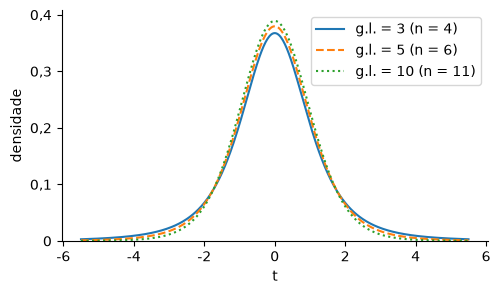

In [5]:
# Distribuições t-Student com 3, 5 e 10 graus de liberdade (n = 4, 6 e 11)
x_graf = np.linspace(-5.5, 5.5, 400)
fig, ax = plt.subplots(figsize=(5.5, 3))
for gl, estilo in ((3, "-"), (5, "--"), (10, ":")):
    ax.plot(x_graf, t.pdf(x_graf, gl), ls=estilo, label=f"g.l. = {gl} (n = {gl + 1})")
ax.set_xlabel("t")
ax.set_ylabel("densidade")
ax.set_ylim(bottom=0)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

2. A distribuição t-Student tem a mesma forma geral de sino da distribuição normal padronizada; sua forma mais aberta reflete a maior variabilidade esperada em pequenas amostras.
    
    Note-se que a distribuição t tem mais área nas caudas.

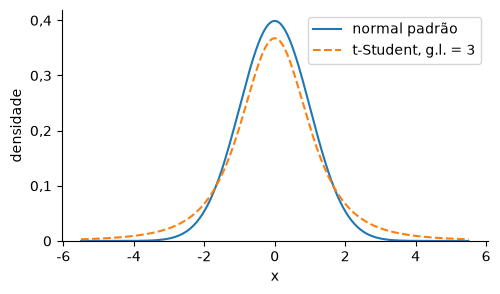

In [6]:
# t-Student com 3 graus de liberdade comparada à normal padrão
x_graf = np.linspace(-5.5, 5.5, 400)
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(x_graf, norm.pdf(x_graf), label="normal padrão")
ax.plot(x_graf, t.pdf(x_graf, 3), ls="--", label="t-Student, g.l. = 3")
ax.set_xlabel("x")
ax.set_ylabel("densidade")
ax.set_ylim(bottom=0)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
virgula(ax)
plt.show()

3. A distribuição t-Student tem média t = 0 (tal como a distribuição normal padronizada, que tem média z = 0).

4. O desvio padrão da distribuição t-Student varia com o tamanho da amostra, e é maior do que 1 (ao contrário da distribuição normal padronizada, em que σ = 1).

5. À medida que o tamanho da amostra aumenta, a distribuição t-Student se aproxima da distribuição normal.

Vimos anteriormente que, para construirmos um intervalo de confiança para a
média é necessário encontrarmos a margem de erro para a estimativa de μ. No caso com σ desconhecido teremos que utilizar a distribuição t-Student, então o cálculo da margem de erro será:

$$E = t_{\alpha/2} \cdot \frac{s}{\sqrt{n}}$$

em que $t_{\alpha/2}$ tem $n - 1$ graus de liberdade.

#### Exemplo:
Com um teste destrutivo, as amostras são destruídas no processo de
teste. O teste de colisão de carros é um exemplo muito dispendioso de teste destrutivo. Suponha que tenhamos feito teste de colisão em 12 carros esporte sob uma diversidade de condições que simulam colisões típicas. A análise dos 12 carros danificados resulta em custos de conserto com média igual a US26.227,00 e um desvio padrão de US15.873,00. Sabe-se que os dados têm distribuição aproximadamente normal.
Determine:

- a) A melhor estimativa pontual de μ, o custo médio de conserto de todos os carros esporte envolvidos em colisões.
- b) A estimativa intervalar de 95% de confiança para μ.

Já sabemos que a melhor estimativa pontual da média populacional (μ) é o valor da média amostral x. Neste caso, a melhor estimativa pontual de μ é US26.227,00.

Devemos construir um intervalo de 95% de confiança utilizando a distribuição t-
Student, porque são verificadas as condições seguintes:
- O desvio padrão da população (σ) é desconhecido
- A população parece ter distribuição normal, porque os dados da amostra têm distribuição aproximadamente normal.

Construindo o intervalo de confiança:

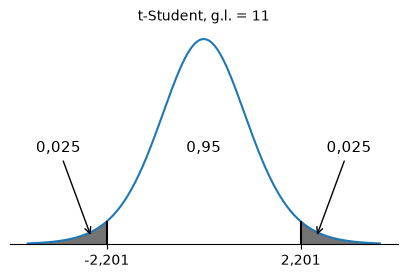

In [7]:
# 95% de confiança com 11 graus de liberdade: 0,025 em cada cauda
duas_caudas(t(11), t.ppf(0.975, 11), ["-2,201", "2,201"], "0,95", "0,025", titulo="t-Student, g.l. = 11")

**Valor crítico:** na tabela t-Student, a linha de $n - 1 = 12 - 1 = 11$ graus de liberdade e a coluna de área $\alpha/2 = 0{,}025$ na cauda superior dão $t_{\alpha/2} = 2{,}201$ (conferido com o `scipy` na célula abaixo).

**Margem de erro:**

$$E = t_{\alpha/2} \cdot \frac{s}{\sqrt{n}} = 2{,}201 \cdot \frac{15873}{\sqrt{12}} \approx 10085{,}29$$

**Intervalo de confiança:**

$$\bar{x} \pm E = 26227 \pm 10085{,}29 \quad \Rightarrow \quad [16141{,}71 ; 36312{,}29]$$

**Interpretação:** com 95% de confiança, o custo médio de conserto dos carros esporte submetidos a esse tipo de colisão está entre 16.141,71 e 36.312,29 dólares.

In [8]:
# Valor crítico t para 95% de confiança e n - 1 = 11 graus de liberdade
from scipy.stats import t

print("t =", round(t.ppf(1 - 0.05 / 2, 11), 3))

t = 2.201


#### Exercício:
Em uma pesquisa de orçamento familiar desenvolvida pelo instituto ZX, solicitou-se a 16 domicílios de certa região que anotassem suas despesas com alimentação durante uma semana. O resultado foi uma despesa média de RS330,00 com um desvio padrão de RS40,00. Construa e interprete um intervalo de 98% de confiança para a verdadeira despesa média semanal com alimentação por domicílio de toda a região. Suponha que a população tenha uma distribuição aproximadamente normal.

In [65]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [70]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]

In [72]:
#Calculando I.C para média quando σ é desconhecido.

#Variáveis do enunciado:
Média_amostral = 330 #reais
N_amostras = 16 #meses
Desvio_amostral = 40 #reais
Grau_de_conf = 98 #(%)
Desvio_populacional = 0 #O enunciado tem apenas desvio amostral,
#por isso o uso de t-student e não z.

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = T(N_amostras, Grau_de_conf)
Desvio_médias_amostrais = Desvio_amostral/(N_amostras**0.5)

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_médias_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Média_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f}" .format(Grau_de_conf, Média_amostral-E, Média_amostral+E))

Valor de Alpha:  0.02
Valor crítico:  2.602
Margem de Erro:  26.02
I.C = [330-26.02 ; 330+26.02]


Pode-se afirmar com 98% de confiança que a média varia de 303.9800 a 356.0200


### Intervalo de confiança para a proporção:
Em muitas situações, o principal parâmetro de interesse é alguma proporção p. Por exemplo:
- A proporção de contas pagas em dia;
- A proporção de atrasos na entrega do produto, etc.
A notação que vamos utilizar é:

- $p$: proporção populacional;
- $\hat{p} = \dfrac{x}{n}$: proporção amostral, em que $x$ é o número de sucessos em uma amostra de tamanho $n$.

Assim como a média amostral é a melhor estimativa pontual para a média
populacional, a proporção amostral (p̂) é a melhor estimativa pontual da proporção populacional (p).

Para encontrarmos o intervalo de confiança para a proporção é necessário
conhecermos que a proporção amostral equivale a uma média aritmética para dados de variáveis do tipo binárias (0 e 1). Assim, as propriedades da distribuição amostral da média também são aplicadas à distribuição amostral da proporção.

Vamos trabalhar com a construção de intervalos de confiança para uma proporção
utilizando a distribuição normal como aproximação da distribuição de proporções
amostrais e, para isso, as suposições n.p̂ >= 5 e n.(1 - p̂) >= 5 precisam, ambas, serem satisfeitas.

A margem de erro é obtida pela multiplicação do valor crítico pelo desvio
padrão das proporções amostrais, conforme a fórmula a seguir:

$$E = z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}}$$

A partir da expressão da margem de erro da proporção e da proporção amostral
encontramos o intervalo de confiança: p̂ +- E

In [1]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [2]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]

In [15]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 125 #peças
Ocorrências = 7 #peças defeituosas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 87 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.13
Valor crítico:  1.51
Margem de Erro:  0.0311
I.C = [0.056-0.0311 ; 0.056+0.0311]


Pode-se afirmar com 87% de confiança que a média varia de   0.0249 a   0.0871 ou, de   2.4900% a   8.7100%


Utilizando o mesmo enunciando do exemplo anterior:
- a) Encontre os intervalos com 80% e 99% de confiança.
       Resposta 80% de confiança:
       z =1,28 ; E=0,0263 ; I.C.=[0,0297 ; 0,0823]
       Resposta 99% de confiança:
       z =2,57 ; E=0,0529 ; I.C.=[0,0031 ; 0,1089]

In [76]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 125 #peças
Ocorrências = 7 #peças defeituosas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 80 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.2
Valor crítico:  1.28
Margem de Erro:  0.0263
I.C = [0.056-0.0263 ; 0.056+0.0263]


Pode-se afirmar com 80% de confiança que a média varia de   0.0297 a   0.0823 ou, de   2.9700% a   8.2300%


In [77]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 125 #peças
Ocorrências = 7 #peças defeituosas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 99 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.01
Valor crítico:  2.57
Margem de Erro:  0.0529
I.C = [0.056-0.0529 ; 0.056+0.0529]


Pode-se afirmar com 99% de confiança que a média varia de   0.0031 a   0.1089 ou, de   0.3100% a  10.8900%


- b) Compare os intervalos obtidos.
       Ao aumentarmos o nível de confiança, houve um aumento da margem de erro e,consequentemente, um aumento da amplitude do intervalo.

#### Exercício 5
A tabela abaixo mostra os resultados de uma pesquisa com 400 homens, 500 mulheres, 650 pessoas que usam frequentemente o forno microondas e 50 pessoas que raramente o usam. Foi perguntado se eles eram favoráveis à irradiação da carne vermelha para matar micróbios transmissores de doenças.

| Grupo | Favoráveis à irradiação |
|---|---|
| Homens | 61% |
| Mulheres | 44% |
| Pessoas que usam o micro-ondas com frequência | 55% |
| Pessoas que raramente usam o micro-ondas | 40% |

Construa um intervalo de 98% de confiança para:
- a) A proporção dos usuários freqüentes do microondas favoráveis à irradiação da carne vermelha. R:z =2,33, [50,45% ; 59,55%]

In [78]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [79]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]

In [80]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 650 #pessoas
Ocorrências = 0.55*N_amostras #pessoas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 98 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.02
Valor crítico:  2.33
Margem de Erro:  0.0455
I.C = [0.55-0.0455 ; 0.55+0.0455]


Pode-se afirmar com 98% de confiança que a média varia de   0.5045 a   0.5955 ou, de  50.4500% a  59.5500%


Construa um intervalo de 98% de confiança para:
- b) A proporção dos usuários esporádicos do microondas favoráveis à irradiação da carne vermelha. R:z =2,33, [23,86% ; 56,14%]

In [81]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 50 #pessoas
Ocorrências = 0.40*N_amostras #pessoas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 98 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.02
Valor crítico:  2.33
Margem de Erro:  0.1614
I.C = [0.4-0.1614 ; 0.4+0.1614]


Pode-se afirmar com 98% de confiança que a média varia de   0.2386 a   0.5614 ou, de  23.8600% a  56.1400%


Construa um intervalo de 98% de confiança para:
- c) A proporção de mulheres que são contra a irradiação da carne vermelha. R:z =2,33, [50,83% ; 61,17%]

In [87]:
#Calculando I.C para a Proporção.

#Variáveis do enunciado:
N_amostras = 500 #pessoas
Ocorrências = 0.56*N_amostras #pessoas
Prop_amostral = Ocorrências/N_amostras #peças defeitusas
Grau_de_conf = 98 #(%)

#Verificação das suposições para a Proporção
if (N_amostras * Prop_amostral >= 5) and (N_amostras * (1-Prop_amostral) >= 5):
    print ("Suposições para I.C da Proporção satifeitas (OK)")
    print("\n")
else:
    print ("Suposições para I.C da Proporção não satifeitas (NOK)")
    print("\n")

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
Desvio_prop_amostrais = ((Prop_amostral * (1-Prop_amostral))/N_amostras)**0.5

#Cálculo da Margem de erro
E = round(Valor_crítico * Desvio_prop_amostrais,4)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("I.C = [{0}-{1} ; {0}+{1}]" .format(Prop_amostral, E))
print("\n")
print("Pode-se afirmar com {0}% de confiança que a média varia de {1:8.4f} a {2:8.4f} ou, de {3:8.4f}% a {4:8.4f}%" .format(Grau_de_conf,Prop_amostral-E,Prop_amostral+E,(Prop_amostral-E)*100,(Prop_amostral+E)*100))

Suposições para I.C da Proporção satifeitas (OK)


Valor de Alpha:  0.02
Valor crítico:  2.33
Margem de Erro:  0.0517
I.C = [0.56-0.0517 ; 0.56+0.0517]


Pode-se afirmar com 98% de confiança que a média varia de   0.5083 a   0.6117 ou, de  50.8300% a  61.1700%


### Determinação do tamanho da amostra:
A expressão para o cálculo do tamanho amostral pode ser obtida a partir da expressão da margem de erro, portanto:

$$E = z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}} \quad \Rightarrow \quad n = \frac{z_{\alpha/2}^2 \cdot \hat{p}(1 - \hat{p})}{E^2}$$

É interessante notar que a expressão acima depende de p̂ que pode ser obtido por meio de um estudo piloto ou de conhecimentos prévios, porém, quando não dispomos de tais informações, podemos atribuir o valor 0,5 para p̂, de forma que o tamanho da amostra resultante seja no mínimo tão grande quanto deveria ser. A razão para atribuir o valor 0,5 é a seguinte: O valor máximo possível do produto p̂.(1-p̂) é 0,25, que ocorre quando p̂ =0,5. Observe a tabela abaixo:

| $\hat{p}$ | $1 - \hat{p}$ | $\hat{p}(1 - \hat{p})$ |
|---|---|---|
| 0,1 | 0,9 | 0,09 |
| 0,2 | 0,8 | 0,16 |
| 0,3 | 0,7 | 0,21 |
| 0,4 | 0,6 | 0,24 |
| **0,5** | **0,5** | **0,25** |
| 0,6 | 0,4 | 0,24 |
| 0,7 | 0,3 | 0,21 |
| 0,8 | 0,2 | 0,16 |
| 0,9 | 0,1 | 0,09 |

Não se esqueça que, se o tamanho da amostra calculado não é um número inteiro,
devemos arredondá-lo para o próximo inteiro mais elevado.

#### Exemplo 6
As companhias de seguro estão ficando preocupadas com o fato de que o número crescente de telefones celulares resulte em maior número de colisões de carros; estão, por isso, pensando em cobrar prêmios mais elevados para os motoristas que utilizam celulares. Desejamos estimar, com uma margem de erro de três pontos percentuais, a percentagem de motoristas que falam ao celular enquanto estão dirigindo. Supondo que se pretende um nível de 95% de confiança nos resultados, quantos motoristas devem ser pesquisados?
- a) Suponha que tenhamos uma estimativa, com base em estudos anteriores, de 18% de motoristas que falam ao celular.
- b) Suponha que não tenhamos qualquer informação que possa sugerir um valor de p̂.

Desejamos estimar o tamanho amostral para um estudo em que o principal parâmetro de interesse é a percentagem de motoristas que falam ao celular enquanto estão dirigindo. No enunciado temos que a margem de erro desejável é de 3% (0,03) e o nível de confiança é de 95%, ou seja, α = 0,05 e z = 1,96.
- a) O estudo anterior sugere que p̂ = 18% = 0,18. Dessa forma:

$$n = \frac{z_{\alpha/2}^2 \cdot \hat{p}(1 - \hat{p})}{E^2} = \frac{1{,}96^2 \cdot 0{,}18 \cdot (1 - 0{,}18)}{0{,}03^2} \approx 630{,}02 \quad \Rightarrow \quad n = 631$$

Devemos pesquisar ao menos 631 motoristas selecionados aleatoriamente.

- b) Como não há conhecimento prévio de c, adotaremos o valor de 0,5:

$$n = \frac{z_{\alpha/2}^2 \cdot \hat{p}(1 - \hat{p})}{E^2} = \frac{1{,}96^2 \cdot 0{,}5 \cdot (1 - 0{,}5)}{0{,}03^2} \approx 1067{,}11 \quad \Rightarrow \quad n = 1068$$

Para termos 95% de confiança de que nossa percentagem amostral está a menos de 3% da verdadeira percentagem de todos os motoristas, devemos selecionar aleatoriamente e pesquisar 1068 motoristas. Comparando este resultado com o tamanho amostral de 631 obtido na letra a), podemos ver que, na ausência de conhecimento prévio, é necessário uma amostra maior para obtermos os mesmos resultados que obteríamos se pudéssemos estimar o valor de p̂.

A expressão:

$$n = \frac{z_{\alpha/2}^2 \cdot \hat{p}(1 - \hat{p})}{E^2}$$

admite que a população é infinita porém, se a população é finita é necessário modificar a margem de erro (E), com a inclusão de um fator de correção para população finita, como segue:

$$E = z_{\alpha/2} \cdot \sqrt{\frac{\hat{p}(1 - \hat{p})}{n}} \cdot \sqrt{\frac{N - n}{N - 1}}$$

onde N é o tamanho da população.

A expressão acima pode ser resolvida em relação à n, dando:

$$n = \frac{N \cdot \hat{p}(1 - \hat{p}) \cdot z_{\alpha/2}^2}{\hat{p}(1 - \hat{p}) \cdot z_{\alpha/2}^2 + (N - 1) \cdot E^2}$$

#### Exemplo 7
O reitor de uma universidade deseja estimar com uma margem de erro de 5% e um nível de confiança de 97%, a proporção de estudantes matriculados nos programas de MBA que fizeram graduação em Sistemas de Informação. Sabe-se que, atualmente, há 550 alunos fazendo MBA. Qual tamanho mínimo de amostra deve ser coletado?
- a) Estima-se que a proporção populacional seja de 23%.
- b) Não há base para estimar o valor aproximado da proporção populacional.

Desejamos estimar o tamanho amostral para um estudo em que o principal parâmetro de interesse é a proporção de estudantes matriculados nos programas de MBA que fizeram graduação em Sistemas de Informação. No enunciado temos que a margem de erro desejável é de 5% (0,05), o nível de confiança é de 97%, ou seja, α=0,03 e z = 2,17.
Além disso, sabe-se que a população de estudo é composta por 550 alunos (N=550).

- a) Estima-se que p̂ = 23% = 0,23. Dessa forma:

$$n = \frac{550 \cdot 0{,}23 \cdot (1 - 0{,}23) \cdot 2{,}17^2}{0{,}23 \cdot (1 - 0{,}23) \cdot 2{,}17^2 + (550 - 1) \cdot 0{,}05^2} \approx 207{,}8774 \quad \Rightarrow \quad n = 208$$

Deve-se amostrar, no mínimo, 208 alunos de MBA para a pesquisa.

- b) Como não há conhecimento prévio de p̂, adotaremos o valor de 0,5:

$$n = \frac{550 \cdot 0{,}5 \cdot (1 - 0{,}5) \cdot 2{,}17^2}{0{,}5 \cdot (1 - 0{,}5) \cdot 2{,}17^2 + (550 - 1) \cdot 0{,}05^2} \approx 253{,}9387 \quad \Rightarrow \quad n = 254$$

Nesse caso teriam que ser amostrados 254 alunos de MBA.

#### Exercício 6
Suponha que você vai realizar um levantamento para estimar a proporção de crianças matriculadas em um programa de saúde infantil na cidade de Nova Lima-MG. Sabe-se, segundo o IBGE, que o município apresentou no ano de 2014 o número de 1286 nascidos vivos e registrados na cidade. Considerando 90% de confiança e um erro amostral de 4%, determine:
- a) O tamanho da amostra. R:n=316,9280, ou seja, 317 crianças.

In [1]:
#Declarando a tabela Z e tabela T-student

t_table = [
[None,0.25,0.125,0.1,0.05,0.025,0.0125,0.01,0.005,0.0025,0.001,0.0005		],
[1,1,2.414,3.078,6.314,12.71,25.45,31.82,63.66,127.3,318.3,636.6            ],
[2,0.817,1.604,1.8856,2.92,4.303,6.205,6.965,9.925,14.09,22.33,31.6         ],
[3,0.765,1.423,1.6377,2.3534,3.182,4.177,4.541,5.841,7.453,10.21,12.92      ],
[4,0.741,1.344,1.5332,2.1319,2.776,3.495,3.747,4.604,5.598,7.173,8.61       ],
[5,0.727,1.301,1.4759,2.0151,2.571,3.163,3.365,4.032,4.773,5.893,6.869      ],
[6,0.718,1.273,1.4398,1.9432,2.447,2.969,3.143,3.707,4.317,5.208,5.959      ],
[7,0.711,1.254,1.4149,1.8946,2.365,2.841,2.998,3.499,4.029,4.785,5.408      ],
[8,0.706,1.24,1.3968,1.8596,2.306,2.752,2.896,3.355,3.833,4.501,5.041       ],
[9,0.703,1.23,1.383,1.8331,2.262,2.685,2.821,3.25,3.69,4.297,4.781          ],
[10,0.7,1.221,1.3722,1.8125,2.228,2.634,2.764,3.169,3.581,4.144,4.587       ],
[11,0.697,1.214,1.3634,1.7959,2.201,2.593,2.718,3.106,3.497,4.025,4.437     ],
[12,0.695,1.209,1.3562,1.7823,2.179,2.56,2.681,3.055,3.428,3.93,4.318       ],
[13,0.694,1.204,1.3502,1.7709,2.16,2.533,2.65,3.012,3.372,3.852,4.221       ],
[14,0.692,1.2,1.345,1.7613,2.145,2.51,2.625,2.977,3.326,3.787,4.14          ],
[15,0.691,1.197,1.3406,1.7531,2.131,2.49,2.602,2.947,3.286,3.733,4.073      ],
[16,0.69,1.194,1.3368,1.7459,2.12,2.473,2.583,2.921,3.252,3.686,4.015       ],
[17,0.689,1.191,1.3334,1.7396,2.11,2.458,2.567,2.898,3.222,3.646,3.965      ],
[18,0.688,1.189,1.3304,1.7341,2.101,2.445,2.552,2.878,3.197,3.611,3.922     ],
[19,0.688,1.187,1.3277,1.7291,2.093,2.433,2.539,2.861,3.174,3.579,3.883     ],
[20,0.687,1.185,1.3253,1.7247,2.086,2.423,2.528,2.845,3.153,3.552,3.85      ],
[21,0.686,1.183,1.3232,1.7208,2.08,2.414,2.518,2.831,3.135,3.527,3.819      ],
[22,0.686,1.182,1.3212,1.7172,2.074,2.405,2.508,2.819,3.119,3.505,3.792     ],
[23,0.685,1.18,1.3195,1.7139,2.069,2.398,2.5,2.807,3.104,3.485,3.768        ],
[24,0.685,1.179,1.3178,1.7109,2.064,2.391,2.492,2.797,3.091,3.467,3.745     ],
[25,0.684,1.178,1.3164,1.7081,2.06,2.385,2.485,2.787,3.078,3.45,3.725       ],
[26,0.684,1.177,1.315,1.7056,2.056,2.379,2.479,2.779,3.067,3.435,3.707      ],
[27,0.684,1.176,1.3137,1.7033,2.052,2.373,2.473,2.771,3.057,3.421,3.69      ],
[28,0.683,1.175,1.3125,1.7011,2.048,2.368,2.467,2.763,3.047,3.408,3.674     ],
[29,0.683,1.174,1.3114,1.6991,2.045,2.364,2.462,2.756,3.038,3.396,3.659     ],
[30,0.683,1.173,1.3104,1.6973,2.042,2.36,2.457,2.75,3.03,3.385,3.646        ],
[31,0.682,1.172,1.3095,1.6955,2.04,2.356,2.453,2.744,3.022,3.375,3.633      ],
[32,0.682,1.172,1.3086,1.6939,2.037,2.352,2.449,2.738,3.015,3.365,3.622     ],
[33,0.682,1.171,1.3077,1.6924,2.035,2.348,2.445,2.733,3.008,3.356,3.611     ],
[34,0.682,1.17,1.307,1.6909,2.032,2.345,2.441,2.728,3.002,3.348,3.601       ],
[35,0.682,1.17,1.3062,1.6896,2.03,2.342,2.438,2.724,2.996,3.34,3.591        ]]

z_table = [
[0.0000,	0.0040,	0.0080,	0.0120,	0.0160,	0.0199,	0.0239,	0.0279,	0.0319,	0.0359],
[0.0398,	0.0438,	0.0478,	0.0517,	0.0557,	0.0596,	0.0636,	0.0675,	0.0714,	0.0753],
[0.0793,	0.0832,	0.0871,	0.0910,	0.0948,	0.0987,	0.1026,	0.1064,	0.1103,	0.1141],
[0.1179,	0.1217,	0.1255,	0.1293,	0.1331,	0.1368,	0.1406,	0.1443,	0.1480,	0.1517],
[0.1554,	0.1591,	0.1628,	0.1664,	0.1700,	0.1736,	0.1772,	0.1808,	0.1844,	0.1879],
[0.1915,	0.1950,	0.1985,	0.2019,	0.2054,	0.2088,	0.2123,	0.2157,	0.2190,	0.2224],
[0.2257,	0.2291,	0.2324,	0.2357,	0.2389,	0.2422,	0.2454,	0.2486,	0.2517,	0.2549],
[0.2580,	0.2611,	0.2642,	0.2673,	0.2704,	0.2734,	0.2764,	0.2794,	0.2823,	0.2852],
[0.2881,	0.2910,	0.2939,	0.2967,	0.2995,	0.3023,	0.3051,	0.3078,	0.3106,	0.3133],
[0.3159,	0.3186,	0.3212,	0.3238,	0.3264,	0.3289,	0.3315,	0.3340,	0.3365,	0.3389],
[0.3413,	0.3438,	0.3461,	0.3485,	0.3508,	0.3531,	0.3554,	0.3577,	0.3599,	0.3621],
[0.3643,	0.3665,	0.3686,	0.3708,	0.3729,	0.3749,	0.3770,	0.3790,	0.3810,	0.3830],
[0.3849,	0.3869,	0.3888,	0.3907,	0.3925,	0.3944,	0.3962,	0.3980,	0.3997,	0.4015],
[0.4032,	0.4049,	0.4066,	0.4082,	0.4099,	0.4115,	0.4131,	0.4147,	0.4162,	0.4177],
[0.4192,	0.4207,	0.4222,	0.4236,	0.4251,	0.4265,	0.4279,	0.4292,	0.4306,	0.4319],
[0.4332,	0.4345,	0.4357,	0.4370,	0.4382,	0.4394,	0.4406,	0.4418,	0.4429,	0.4441],
[0.4452,	0.4463,	0.4474,	0.4484,	0.4495,	0.4505,	0.4515,	0.4525,	0.4535,	0.4545],
[0.4554,	0.4564,	0.4573,	0.4582,	0.4591,	0.4599,	0.4608,	0.4616,	0.4625,	0.4633],
[0.4641,	0.4649,	0.4656,	0.4664,	0.4671,	0.4678,	0.4686,	0.4693,	0.4699,	0.4706],
[0.4713,	0.4719,	0.4726,	0.4732,	0.4738,	0.4744,	0.4750,	0.4756,	0.4761,	0.4767],
[0.4772,	0.4778,	0.4783,	0.4788,	0.4793,	0.4798,	0.4803,	0.4808,	0.4812,	0.4817],
[0.4821,	0.4826,	0.4830,	0.4834,	0.4838,	0.4842,	0.4846,	0.4850,	0.4854,	0.4857],
[0.4861,	0.4864,	0.4868,	0.4871,	0.4875,	0.4878,	0.4881,	0.4884,	0.4887,	0.4890],
[0.4893,	0.4896,	0.4898,	0.4901,	0.4904,	0.4906,	0.4909,	0.4911,	0.4913,	0.4916],
[0.4918,	0.4920,	0.4922,	0.4925,	0.4927,	0.4929,	0.4931,	0.4932,	0.4934,	0.4936],
[0.4938,	0.4940,	0.4941,	0.4943,	0.4945,	0.4946,	0.4948,	0.4949,	0.4951,	0.4952],
[0.4953,	0.4955,	0.4956,	0.4957,	0.4959,	0.4960,	0.4961,	0.4962,	0.4963,	0.4964],
[0.4965,	0.4966,	0.4967,	0.4968,	0.4969,	0.4970,	0.4971,	0.4972,	0.4973,	0.4974],
[0.4974,	0.4975,	0.4976,	0.4977,	0.4977,	0.4978,	0.4979,	0.4979,	0.4980,	0.4981],
[0.4981,	0.4982,	0.4982,	0.4983,	0.4984,	0.4984,	0.4985,	0.4985,	0.4986,	0.4986],
[0.4987,	0.4987,	0.4987,	0.4988,	0.4988,	0.4989,	0.4989,	0.4989,	0.4990,	0.4990],
[0.4990,	0.4991,	0.4991,	0.4991,	0.4992,	0.4992,	0.4992,	0.4992,	0.4993,	0.4993],
[0.4993,	0.4993,	0.4994,	0.4994,	0.4994,	0.4994,	0.4994,	0.4995,	0.4995,	0.4995],
[0.4995,	0.4995,	0.4995,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4996,	0.4997],
[0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4997,	0.4998],
[0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998,	0.4998]]

In [2]:
# Definindo as funções de busca dos valores Z e T nas tabelas

def Z(Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    Grau_de_conf = abs(Grau_de_conf / 2.0)
    ri = 0
    rj = 0
    rdiff = 2
    for i in range(len(z_table)):
        for j in range(len(z_table[i])):
            diff = abs(z_table[i][j] - Grau_de_conf)
            if(diff < rdiff):
                ri = i
                rj = j
                rdiff = diff
    return round(ri * 0.1 + rj * 0.01, 2)

def T(N, Grau_de_conf):
    Grau_de_conf = Grau_de_conf/100
    N = N-1
    Grau_de_conf = round(0.5 - abs(Grau_de_conf / 2), 3)
    ri = -1
    rj =  -1
    
    for j in range(len(t_table[0])):
        if(Grau_de_conf == t_table[0][j]):
            rj = j
            break
    for i in range(len(t_table)):
        if(N == t_table[i][0]):
            ri = i
            break
    if(ri == -1 or rj == -1):
        print('ERROR!!!!!!!')
    return t_table[ri][rj]

In [8]:
#Calculando Número de amostras (N) para a Proporção.

import numpy as np

#Variáveis do enunciado:
Erro = 4 #%  Margem de erro em %
Proporção_amostral = 50 #%  p̂ de 50% quando não dado no enunciado
Grau_de_conf = 90 #(%)

N_finita = True
N_populacional = 1286 #pessoas

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
E = Erro/100
Prop_amostral = Proporção_amostral/100

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * (Prop_amostral * (1-Prop_amostral)) * Valor_crítico**2) / 
    (((Prop_amostral * (1-Prop_amostral)) * Valor_crítico**2) + ((N_populacional -1) * E**2)))
else:
    N_amostras = np.ceil((Valor_crítico**2 * (Prop_amostral * (1-Prop_amostral))) / E**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Proporção amostral: ",Prop_amostral)
print("\n")
print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  0.04
Proporção amostral:  0.5


O número de amostras ideal é:  317.0


- b) Considerando agora uma proporção de 70% de crianças matriculadas no programa de saúde, qual seria o tamanho da amostra? R:n=277,1478, ou seja, 278 crianças.

In [9]:
#Calculando Número de amostras (N) para a Proporção.

import numpy as np

#Variáveis do enunciado:
Erro = 4 #%  Margem de erro em %
Proporção_amostral = 70 #%  p̂ de 50% quando não dado no enunciado
Grau_de_conf = 90 #(%)

N_finita = True
N_populacional = 1286 #pessoas

#Cálculos de variáveis secundárias
Alpha = round(1-(Grau_de_conf/100),3)
Valor_crítico = Z(Grau_de_conf)
E = Erro/100
Prop_amostral = Proporção_amostral/100

#Cálculo do Número de amostras
if N_finita:
    N_amostras = np.ceil((N_populacional * (Prop_amostral * (1-Prop_amostral)) * Valor_crítico**2) / 
    (((Prop_amostral * (1-Prop_amostral)) * Valor_crítico**2) + ((N_populacional -1) * E**2)))
else:
    N_amostras = np.ceil((Valor_crítico**2 * (Prop_amostral * (1-Prop_amostral))) / E**2)

print("Valor de Alpha: ",Alpha)
print("Valor crítico: ",Valor_crítico)
print("Margem de Erro: ",E)
print("Proporção amostral: ",Prop_amostral)
print("\n")
print("O número de amostras ideal é: ",N_amostras)

Valor de Alpha:  0.1
Valor crítico:  1.64
Margem de Erro:  0.04
Proporção amostral:  0.7


O número de amostras ideal é:  278.0
